# Gather all information pertaining to abx use and covariate information

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from itertools import combinations
from tableone import TableOne

# apply settings so the lib knows where the data is
import arivale_data_interface as adi
adi.apply_isb_config()

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Start by harmonizing questionnaire data

## Read larger questionnaire first

In [2]:
medication_assessments = adi.get_snapshot('assessments_medications')
medication_assessments.dropna(subset=['meds_antibiotics_last_3_months','days_in_program'],
                              inplace=True)

In [3]:
medication_assessments.public_client_id.nunique()

5229

In [4]:
# Binary usage of abx, glucose, chol meds
abx_three_mo_df = medication_assessments[['public_client_id', 'days_in_program', 
                                          'meds_antibiotics_last_3_months', 'meds_blood_sugar',
                                          'meds_cholesterol']].copy()
abx_three_mo_df.public_client_id.nunique()

5229

In [5]:
abx_three_mo_df.meds_antibiotics_last_3_months.value_counts()

meds_antibiotics_last_3_months
No     5794
Yes     863
Name: count, dtype: int64

## Let's drop duplicates in the larger snapshot
Snapshot = `medication_assessments`

Aim to keep the first index or choose the abx-use index if there are only 2 appearances

In [6]:
# Try using stool sample data to select for timepoint where folks provide stool
all_counts = pd.read_csv("data/arivale_16S_genera_counts.csv", dtype={'public_client_id':str})

# Sort
all_counts = all_counts.sort_values(by='days_in_program')
abx_three_mo_df = abx_three_mo_df.sort_values(by='days_in_program')

In [7]:
select_samples = pd.merge_asof(
    abx_three_mo_df, all_counts, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30).dropna(subset="Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia")

In [8]:
select_samples.public_client_id.nunique()

2763

In [9]:
len(select_samples)

2925

In [10]:
indices_to_drop = []
clients_checked = []
mixed_y_n = []

for client in select_samples['public_client_id']:
    if client not in clients_checked:
        clients_checked.append(client)
        rows = select_samples[select_samples['public_client_id'] == client]
        abx_count = (rows['meds_antibiotics_last_3_months'] != 'No').sum()
        if abx_count == 0: 
            rows.sort_values(by="days_in_program") 
            # First instance will be the 0th index
            result_index = rows['days_in_program'].index[1:]
            integer_values = [int(idx) for idx in result_index]
            indices_to_drop.append(integer_values)
        
        if abx_count == 1: # Drop any No indeces
            no_abx_indices = rows[rows['meds_antibiotics_last_3_months'] == 'No'].index
            integer_values = [int(idx) for idx in no_abx_indices]
            indices_to_drop.append(integer_values)  # To drop the duplicate
            mixed_y_n.append(client)

drop_list = [item for sublist in indices_to_drop for item in sublist]

In [11]:
len(drop_list)

157

### Let's proceed to drop those duplicates as specified above
- Keep first instance of "No"
- Keep any instance of "Yes", but we've saved the rows for the late abx users above
- Below we will drop any "Yes" duplicates, keeping the first instance

In [12]:
select_samples.drop(drop_list, inplace = True)

In [13]:
select_samples.public_client_id.nunique()

2763

In [14]:
len(select_samples)

2768

In [15]:
left_over = select_samples.public_client_id[select_samples.public_client_id.duplicated()]

# As suspected, these folks use abx multiple times
# We should make sure they are not used for LMMs
# However, here can simply keep first index
check_muliple_use = (select_samples[
                     select_samples.public_client_id.isin(left_over)
                     ].sort_values(by='public_client_id'))
check_muliple_use.to_csv('data/abx_multiple_use_df.csv')

In [16]:
# This keeps first instance for those who may use antibiotics more than once
select_samples = select_samples.loc[lambda x: ~x.public_client_id.duplicated(keep='first')]

In [17]:
len(select_samples) # Yay!

2763

In [18]:
three_mo_qs_filtered = select_samples.iloc[:, 0:5].copy()

## Now let's harmonize the second questionnaire

In [19]:
past_year = adi.get_snapshot('assessments_vitals')[['public_client_id',
                                                    'days_in_program',
                                                    'assessment:vitals:antibiotics:enum',
                                                    'assessment:vitals:blood_sugar:enum',
                                                    'assessment:vitals:cholesterol:enum']].copy()
past_year.public_client_id.nunique()

3134

In [20]:
past_year.dropna(
    subset=['assessment:vitals:antibiotics:enum', 'days_in_program'],
    inplace=True)
past_year.public_client_id.nunique()

3129

In [21]:
# Shorten and rename so col has no colons
past_year.rename(columns={'assessment:vitals:antibiotics:enum':'abx_recency',
                          'assessment:vitals:blood_sugar:enum':'blood_sugar_enum',
                          'assessment:vitals:cholesterol:enum':'cholesterol_enum'}, 
                 inplace=True)

In [22]:
# Shorten answers
mapping = {'(0) In the last 3 months': 'three',    # For antibiotics
           '(1) In the last 12 months': 'twelve', 
           '(2) Not in the last year': 'none',
           '(0) More than once per day': 'daily+', # For blood sugar/cholesterol
           '(1) Daily': 'daily',
           '(2) Occasionally when needed': 'occasionally',
           '(3) Not at all': 'none',
          }

past_year['abx_recency'] = past_year['abx_recency'].map(mapping)
past_year['blood_sugar_enum'] = past_year['blood_sugar_enum'].map(mapping)
past_year['cholesterol_enum'] = past_year['cholesterol_enum'].map(mapping)

In [23]:
harmonize_abx_qs = pd.merge(three_mo_qs_filtered, past_year, 
                            on=["public_client_id", "days_in_program"], 
                            how="outer")
len(harmonize_abx_qs)

3923

In [24]:
harmonize_abx_qs.public_client_id.nunique()

3867

Okay so there do seem to be some duplicates. 

In [25]:
merged_dup_list = (harmonize_abx_qs[
                   harmonize_abx_qs.public_client_id.duplicated()
                   ].public_client_id.tolist())

merged_dup_df = (harmonize_abx_qs[
                 harmonize_abx_qs.public_client_id.isin(merged_dup_list)
                 ].sort_values(by=['public_client_id','days_in_program'], kind='mergesort'))
len(merged_dup_df)

112

In [26]:
# merged_dup_df.head()

Importantly, we are observing that these are mostly instances where an individual completed a survey but filled out one row but not the other! We should be able to sort through these and harmonize. Our goal should be to retain the antibiotic users for which we have high quality information—anything in the `abx_recency` and when `meds_antibiotics_last_3_months` == `Yes` (Because `No` can be either none or twelve month recency, for example).

In [27]:
harmonize_abx_qs['abx_recency'].value_counts()

abx_recency
none      1961
twelve     721
three      449
Name: count, dtype: int64

In [28]:
harmonize_abx_qs['meds_antibiotics_last_3_months'].value_counts()

meds_antibiotics_last_3_months
No     2421
Yes     342
Name: count, dtype: int64

In [29]:
# First we can impute those who do use antibiotics in the last 3 months into abx_recency
harmonize_abx_qs.loc[
(harmonize_abx_qs['meds_antibiotics_last_3_months'] == 'Yes') &
(harmonize_abx_qs.abx_recency.isna()), 'abx_recency'] = 'three'

In [30]:
harmonize_abx_qs['abx_recency'].value_counts()

abx_recency
none      1961
twelve     721
three      529
Name: count, dtype: int64

Let's additionally prioritize the individuals/timepoints who response to the `abx_recency` question, as that information is higher quality. Remove the indeces that are NaN in the `meds_antibiotics_last_3_months` but not null in the `abx_recency` column.

In [31]:
meds_assessment_null_idx = merged_dup_df[(                    # Grabs the index
    (merged_dup_df['meds_antibiotics_last_3_months'].isna())  # Of those with NA in meds_antibiotics_last_3_months
    & (merged_dup_df.abx_recency.notna()))].index             # With complete data in `abx_recency`

In [32]:
abx_harmonized_final = harmonize_abx_qs.drop(meds_assessment_null_idx) 

In [33]:
len(abx_harmonized_final)

3867

In [34]:
abx_harmonized_final.public_client_id.nunique()

3867

In [35]:
abx_harmonized_final.abx_recency.isna().sum()

712

Looks like there are 712 individuals for which it is not possible to resolve whether they took antibiotics in the last 3 months or the last year. Let's look at the distribition of `abx_recency` for the data we do have.

In [36]:
abx_harmonized_final.abx_recency.value_counts()

abx_recency
none      1932
twelve     709
three      514
Name: count, dtype: int64

In [37]:
# Okay awesome, so this is the shared number of folks
pd.crosstab(abx_harmonized_final['meds_antibiotics_last_3_months'], abx_harmonized_final['abx_recency'])

abx_recency,none,three,twelve
meds_antibiotics_last_3_months,,,
No,1263,0,446
Yes,0,342,0


Okie dokie we should drop our ambiguous data, meaning the NaNs for `abx_recency` and the one individual that has a conflict in their response.

In [38]:
(abx_harmonized_final.public_client_id.nunique()) - (abx_harmonized_final.abx_recency.isna().sum())

3155

In [39]:
abx_harmonized_final = abx_harmonized_final.dropna(subset='abx_recency')

**Total number of individuals dropped because of ambigiuty/we couldn't resolve the 12mo- from none is 712**

## Assess distribution of meds for cholesterol and glucose

Before dropping NaNs in these covars we have the following N:

In [40]:
before_mets_med_drop = len(abx_harmonized_final)

In [41]:
# Imputing known values from the columns in questionnaire 2 
abx_harmonized_final.loc[
(abx_harmonized_final['blood_sugar_enum'] == 'none') &
(abx_harmonized_final.meds_blood_sugar.isna()), 'meds_blood_sugar'] = 'No'

abx_harmonized_final.loc[
(abx_harmonized_final['cholesterol_enum'] == 'none') &
(abx_harmonized_final.meds_cholesterol.isna()), 'meds_cholesterol'] = 'No'

abx_harmonized_final.loc[
(abx_harmonized_final['blood_sugar_enum'].notna()) &
(abx_harmonized_final['blood_sugar_enum'] != 'none') &
(abx_harmonized_final.meds_cholesterol.isna()), 'meds_blood_sugar'] = 'Yes'

abx_harmonized_final.loc[
(abx_harmonized_final['cholesterol_enum'].notna()) &
(abx_harmonized_final['cholesterol_enum'] != 'none') &
(abx_harmonized_final.meds_cholesterol.isna()), 'meds_cholesterol'] = 'Yes'

In [42]:
abx_harmonized_final.meds_blood_sugar.isna().sum()

29

In [43]:
abx_harmonized_final.meds_cholesterol.isna().sum()

5

In [44]:
pd.crosstab(abx_harmonized_final['meds_blood_sugar'], abx_harmonized_final['blood_sugar_enum'])

blood_sugar_enum,daily,daily+,none,occasionally
meds_blood_sugar,,,,
No,0,0,2947,0
Yes,53,45,0,6


In [45]:
pd.crosstab(abx_harmonized_final['meds_cholesterol'], abx_harmonized_final['cholesterol_enum'])

cholesterol_enum,daily,daily+,none,occasionally
meds_cholesterol,,,,
No,0,0,2728,0
Yes,317,7,0,23


In [46]:
abx_harmonized_final['meds_blood_sugar'].value_counts()

meds_blood_sugar
No     3016
Yes     110
Name: count, dtype: int64

In [47]:
# Let's add false negatives for glucose meds identified from free text
blood_sugar_text = pd.read_csv('data/arivale_meds_blood_sugar_free_text.csv',
                             dtype={'public_client_id':str})

In [48]:
abx_harmonized_final.loc[
(abx_harmonized_final['public_client_id'].isin(
    blood_sugar_text.public_client_id)), 'meds_blood_sugar'] = 'Yes'

In [49]:
abx_harmonized_final['meds_blood_sugar'].value_counts()

meds_blood_sugar
No     3004
Yes     123
Name: count, dtype: int64

Okay, we see great agreement! Let's drop the new folks with missing additional medication data.

In [50]:
abx_harmonized_final = abx_harmonized_final.dropna(subset=['meds_blood_sugar','meds_cholesterol'])

In [51]:
# Dropped due to NaNs in 
before_mets_med_drop - len(abx_harmonized_final)

28

In [52]:
# Let's drop redundant columns in 'meds_blood_sugar','meds_cholesterol'
abx_harmonized_final = abx_harmonized_final.drop(columns=['cholesterol_enum', 'blood_sugar_enum','meds_antibiotics_last_3_months'])

In [53]:
len(abx_harmonized_final)

3127

# Add sex, age, BMI data

In [54]:
# Sex and age
clients = adi.get_snapshot("clients")[["public_client_id", "sex", "age"]].copy()
clients.public_client_id.nunique()

6133

In [55]:
len(set(abx_harmonized_final.public_client_id) - set(clients.public_client_id))

113

Looks like there's 113 people for which we have no age and sex data

In [56]:
abx_sex_age = pd.merge(abx_harmonized_final, clients, on="public_client_id", how="inner")
len(abx_sex_age)

3014

In [57]:
# BMI
weights = adi.get_snapshot("weight")[["BMI_CALC", "public_client_id", "days_in_program"]].dropna()
weights = weights[weights.public_client_id.isin(abx_sex_age.public_client_id)]
weights = weights.sort_values(by="days_in_program")
abx_sex_age = abx_sex_age.sort_values(by="days_in_program")

In [58]:
clients_BMI = pd.merge_asof(
    abx_sex_age,
    weights.sort_values(by="days_in_program"), 
    by="public_client_id",
    on="days_in_program",
    direction="nearest")

**total missing BMI data is as follows:**

In [59]:
len(abx_sex_age.public_client_id) - len(clients_BMI.public_client_id) # Wow awesome!

0

In [60]:
len(clients_BMI)

3014

# Look at health history data

In [61]:
health_status = pd.read_csv("data/health_history_consolidated.csv")
health_status_small = health_status[[
    'public_client_id','days_in_program','type2_diabetes_current',
    'elevated_cholesterol_current','type1_diabetes_current',
    'elevated_cholesterol_past', 'type2_diabetes_past']].copy()

In [62]:
health_status_small.type1_diabetes_current.value_counts()

type1_diabetes_current
FALSE       6580
TRUE          22
CONFLICT       2
Name: count, dtype: int64

In [63]:
t1dm_clients = health_status_small[(
    (health_status_small.type1_diabetes_current == 'TRUE') | 
    (health_status_small.type1_diabetes_current == 'CONFLICT'))].public_client_id.tolist()

Let's drop individuals with current or conflicted reports of T1DM since the group is so small.

In [64]:
abx_no_t1dm = clients_BMI[~(clients_BMI.public_client_id.isin(t1dm_clients))]

In [65]:
len(clients_BMI) - len(abx_no_t1dm)

11

In [66]:
abx_no_t1dm.to_csv('data/abx_cohort_age_sex_bmi_only.csv', index=False)

In [67]:
len(abx_no_t1dm)

3003

# Let's add the PCs for genetic ancestry

In [68]:
ancestry = adi.get_snapshot('genetics_ancestry')[['public_client_id','PC1', 'PC2', 'PC3','PC4', 'PC5']].copy()

In [69]:
cols_to_scale = ['PC1','PC2','PC3','PC4','PC5']

In [70]:
ancestry[cols_to_scale] = ancestry[cols_to_scale] * 10

Because the PCs of ancestry are small values like "0.003376", these appear in scale to be very different from a covariate such as age. In order to avoid a large condition number, I am going to multiply these columns by 10 in order to rescale them. 

In [71]:
abx_ancestry = pd.merge(ancestry, abx_no_t1dm, on="public_client_id", how="inner")

**Sad, looks like there's 352 people missing genetic ancestry data**

In [72]:
len(set(abx_no_t1dm.public_client_id) - set(ancestry.public_client_id))

312

In [73]:
len(abx_ancestry)

2691

## Add GFR data

In [74]:
labs = adi.get_snapshot('chemistries', clean=True) # Not sure the clean param is working
labs.columns = labs.columns.str.replace(', ', '_')
labs.columns = labs.columns.str.replace('-', '_')
labs.columns = labs.columns.str.replace('/', '_')
labs.columns = labs.columns.str.replace(' ', '')
labs.columns = labs.columns.str.replace('(', '_')
labs.columns = labs.columns.str.replace(')', '_')
labs.head()

,public_client_id,vendor,vendor_observation_id,observation_id,reflexive,fasting,days_in_program,days_since_first_call,days_since_first_draw,month,...,VITAMIND3_25_OH,VLDLLDLPARTICLENUMBER,VLDLPARTICLENUMBER,VLDLSIZEPERCENTILE,VLDLTRIGLYCERIDES,WHITECELLCOUNT,ZINC,ZINC_RBC,leptin,zinc_plasma_or_serum
0,01000261,Quest,YH289668,10271,False,TRUE,65,-9.0,0,Jan,...,58.0,NaN,NaN,NaN,NaN,5.9,980.0,9.8,NaN,NaN
1,01000261,LCA,B0040998784,65656,False,TRUE,198,124.0,133,May,...,NaN,1753.0,45.5,48.9,69.1,4.9,1410.0,NaN,NaN,NaN
2,01001298,LCA,AV27365801,2837393,False,TRUE,7,0.0,0,Sep,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,01001467,LCA,AV29176623,2500980,False,TRUE,15,1.0,0,Jun,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,01001467,LCA,AV29431391,3306809,True,TRUE,223,209.0,208,Jan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [75]:
# Drop users that aren't fasting for the blood draw
labs = labs[labs['fasting']=="TRUE"]

# Change type to be compatible for merge
labs.days_in_program = labs.days_in_program.astype('float64')
labs.days_in_program.dtype 

labs_gfr = labs[['public_client_id','days_in_program','GFR_MDRD','CREATININEENZ_SER']].copy()

Here I made the tolerance 90 days as I think of GFR as a slow changing metric, especially given the Arivale population is a healthy subset of people. According to Nojima et al. 2017 (PMID: 29129852), "GFR generally declines at a rate of 1 mL/min/year." So a tolerance of 90 days would but is within 1ml of the Arivale measure. 

In [76]:
labs_gfr = labs_gfr.sort_values(by="days_in_program")
abx_ancestry = abx_ancestry.sort_values(by="days_in_program")

# Merge with measure
abx_covariates = pd.merge_asof(
    abx_ancestry, labs_gfr, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest").dropna() # subset=['CREATININEENZ_SER','abx_recency']
abx_covariates

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,sex,age,BMI_CALC,GFR_MDRD,CREATININEENZ_SER
0,01071494,-0.216793,-0.110133,-0.088564,0.055447,0.006009,-40.0,No,No,none,F,49.0,30.598898,84.0,0.83
1,01568974,-0.149388,0.030381,0.617446,0.176120,0.042827,-7.0,No,No,twelve,F,46.0,35.662071,115.0,0.53
2,01092042,-0.503311,-0.208429,-0.160230,-0.046219,0.061394,-7.0,No,No,none,F,54.0,19.483497,99.0,0.69
3,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,M,45.0,26.120098,84.0,1.06
4,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,M,32.0,22.668163,93.0,1.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2686,01181682,0.058783,-0.010586,-0.012099,-0.051793,0.031362,629.0,No,Yes,twelve,M,49.0,24.676735,67.0,1.25
2687,01201199,0.065988,-0.013680,-0.050926,0.044681,0.035107,712.0,No,No,three,F,42.0,32.413454,95.0,0.77
2688,01440344,-0.490879,-0.196570,-0.115884,-0.019040,0.133794,731.0,No,Yes,three,F,47.0,23.957596,96.0,0.74
2689,01382823,0.065718,-0.021335,-0.035135,0.089997,0.031969,752.0,No,No,three,F,47.0,30.724246,103.0,0.70


**Number of people without lab data for GFR**

In [77]:
len(abx_no_t1dm) - len(abx_covariates)

334

In [78]:
# abx_no_t1dm # Could save this CSV for other analyses if want more power?

Calculate GFR using 2021 equation: https://www.kidney.org/professionals/ckd-epi-creatinine-equation-2021

In [79]:
# Set K and alpha based on sex
abx_covariates["K"] = np.where(abx_covariates["sex"] == "F", 0.7, 0.9)
abx_covariates["alpha"] = np.where(abx_covariates["sex"] == "F", -0.241, -0.302)

# Female multiplier (1.012 if female, else 1)
abx_covariates["female_multiplier"] = np.where(abx_covariates["sex"] == "F", 1.012, 1.0)

# Standardized Scr / K
scr_k = abx_covariates["CREATININEENZ_SER"] / abx_covariates["K"]

# Apply formula
abx_covariates["eGFR"] = (
    142
    * np.minimum(scr_k, 1) ** abx_covariates["alpha"]
    * np.maximum(scr_k, 1) ** (-1.200)
    * (0.9938 ** abx_covariates["age"])
    * abx_covariates["female_multiplier"]
)

<Axes: xlabel='GFR_MDRD', ylabel='eGFR'>

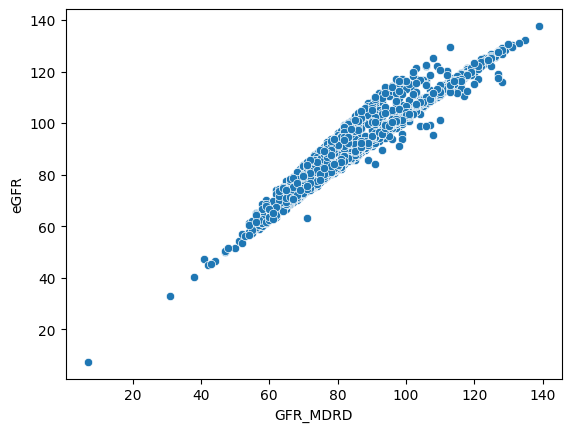

In [80]:
sns.scatterplot(data=abx_covariates, x='GFR_MDRD', y='eGFR')

The scale of the GFR variable is larger than all other covariates (even age), so I am going to mean center this variable for scale.

In [81]:
abx_covariates['centered_eGFR'] = abx_covariates['eGFR'].apply(lambda x: x - abx_covariates['eGFR'].mean())
abx_covariates['centered_BMI'] = abx_covariates['BMI_CALC'].apply(lambda x: x - abx_covariates['BMI_CALC'].mean())

In [82]:
abx_covariates['centered_eGFR'].isna().sum()

0

In [83]:
abx_covariates['abx_recency_three'] = abx_covariates['abx_recency'].apply(
    lambda x: 1 if x == 'three' else 0)

abx_covariates['abx_recency_twelve'] = abx_covariates['abx_recency'].apply(
    lambda x: 1 if x == 'twelve' else 0)

In [84]:
abx_covariates.columns

Index(['public_client_id', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5',
       'days_in_program', 'meds_blood_sugar', 'meds_cholesterol',
       'abx_recency', 'sex', 'age', 'BMI_CALC', 'GFR_MDRD',
       'CREATININEENZ_SER', 'K', 'alpha', 'female_multiplier', 'eGFR',
       'centered_eGFR', 'centered_BMI', 'abx_recency_three',
       'abx_recency_twelve'],
      dtype='object')

Awesome, time to drop the helper columns!

In [85]:
abx_covariates.drop(columns=['alpha', 'K', 'female_multiplier',
                             'CREATININEENZ_SER', 'GFR_MDRD'], inplace=True)

In [86]:
abx_covariates.abx_recency.value_counts()

abx_recency
none      1647
twelve     593
three      429
Name: count, dtype: int64

In [87]:
# abx_covariates.days_in_program.describe()

# Save CSV

In [88]:
# This will have the entire cohort with N = 2669
abx_covariates.to_csv("data/abx_recency_covariates_all.csv", index=False)

# Create TableOne

In [89]:
columns = ['age', 'sex', 'BMI_CALC', 'eGFR', 'meds_blood_sugar', 'meds_cholesterol']
continuous = ['age','BMI_CALC', 'eGFR']
categorical = ['sex', 'meds_blood_sugar', 'meds_cholesterol']
groupby = 'abx_recency'

table1 = TableOne(abx_covariates, columns=columns, 
                  categorical=categorical, continuous=continuous,
                  groupby=groupby, pval=True, htest_name=True)
table1

Grouped by abx_recency                                                                           
                                           Missing      Overall         none        three       twelve P-Value           Test
n                                                          2669         1647          429          593                       
age, mean (SD)                                   0  47.8 (11.8)  47.6 (11.6)  48.4 (12.4)  47.8 (11.9)   0.450  One-way ANOVA
sex, n (%)              F                           1625 (60.9)   965 (58.6)   289 (67.4)   371 (62.6)   0.003    Chi-squared
                        M                           1044 (39.1)   682 (41.4)   140 (32.6)   222 (37.4)                       
BMI_CALC, mean (SD)                              0   27.9 (6.4)   27.4 (6.0)   28.4 (7.0)   28.7 (6.7)  <0.001  One-way ANOVA
eGFR, mean (SD)                                  0  96.9 (14.8)  97.1 (14.8)  96.7 (14.8)  96.8 (14.9)   0.840  One-way ANOVA
meds_blood_sugar, n (%) No                          2561 (96.0)  1591 (96.6)   406 (94.6)   564 (95.1)   0.092    Chi-squared
                        Yes                           108 (4.0)     56 (3.4)     23 (5.4)     29 (4.9)                       
meds_cholesterol, n (%) No                          2338 (87.6)  1479 (89.8)   357 (83.2)   502 (84.7)  <0.001    Chi-squared
                        Yes                          331 (12.4)   168 (10.2)    72 (16.8)    91 (15.3)

In [90]:
excel_table = 'figures/tableone_abx_cohort_all.xlsx'
table1.to_excel(excel_table)

# Check participation in Arivale Scientific Wellness Cohort

In [91]:
clients_program = adi.get_snapshot("clients")[["public_client_id", "latest_program"]].copy()

In [92]:
clients_sws = clients_program[clients_program['latest_program'] ==  'Arivale-Providence Feasibility Study of Scientific Wellness']

In [93]:
abx_sws = abx_covariates[abx_covariates['public_client_id'].isin(clients_sws.public_client_id)].copy()

In [94]:
len(abx_sws)

803

In [95]:
abx_sws.abx_recency.value_counts()

abx_recency
none      495
twelve    178
three     130
Name: count, dtype: int64

# Check to see if there is good stool sample distribution
This will also be useful for adding the stool vendor (if person will eventually provide a stool sample)

In [96]:
shannon_div = adi.get_snapshot("microbiome_diversity").dropna(subset='days_in_program')
shannon_div = shannon_div[['public_client_id','days_in_program','diversity_shannon', 'vendor_dashboard']].copy()

We will want to do this with the full set of covariates and the basic (age, sex, BMI, and med use) covariates.

In [97]:
# Sort values
shannon_div = shannon_div.sort_values(by="days_in_program")
abx_covariates = abx_covariates.sort_values(by="days_in_program")
abx_no_t1dm = abx_no_t1dm.sort_values(by="days_in_program")

In [98]:
# Merge with all
abx_covar_stool_all = pd.merge_asof(
    abx_covariates, shannon_div, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30).dropna(subset='diversity_shannon')

In [99]:
# Merge with basic
abx_covar_stool_basic = pd.merge_asof(
    abx_no_t1dm, shannon_div, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30).dropna(subset='diversity_shannon')

In [117]:
# abx_covar_stool_basic

In [100]:
# abx_covar_stool.diversity_shannon.isna().sum() # differential between my all covars and with stool available

In [101]:
# abx_stool_complete = abx_covar_stool.dropna(subset='diversity_shannon')

# len(abx_stool_complete)

# Look at statin users (with and without stool info is okay)
Some of these folks might have Hba1c data and others may have stool

In [102]:
statin_users = pd.read_csv('data/arivale_statin_users.csv', dtype={"public_client_id":str, "days_in_program":float})

In [104]:
statin_users = statin_users.sort_values(by="days_in_program")
abx_covar_stool_all = abx_covar_stool_all.sort_values(by="days_in_program")
abx_covar_stool_basic = abx_covar_stool_basic.sort_values(by="days_in_program")

In [131]:
# Merge with all
abx_covar_stool_all_statin = pd.merge_asof(
    abx_covar_stool_all, statin_users, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30)

# Basic
abx_covar_stool_basic_statin = pd.merge_asof(
    abx_covar_stool_basic, statin_users, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest", 
    tolerance=30)

In [121]:
# We should fix this agreement
pd.crosstab(abx_covar_stool_all_statin['meds_cholesterol'], abx_covar_stool_all_statin['statin'])

statin,atorvastatin,fluvastatin,lovastatin,pitavastatin,pravastatin,rosuvastatin,simvastatin
meds_cholesterol,,,,,,,
No,0,0,1,0,1,0,2
Yes,99,1,11,2,8,31,35


In [132]:
abx_covar_stool_all_statin.loc[
(abx_covar_stool_all_statin['meds_cholesterol'] == 'No') &
(abx_covar_stool_all_statin.statin.notna()), 'meds_cholesterol'] = 'Yes'

abx_covar_stool_basic_statin.loc[
(abx_covar_stool_basic_statin['meds_cholesterol'] == 'No') &
(abx_covar_stool_basic_statin.statin.notna()), 'meds_cholesterol'] = 'Yes'

In [123]:
pd.crosstab(abx_covar_stool_all_statin['meds_cholesterol'], abx_covar_stool_all_statin['statin'])

statin,atorvastatin,fluvastatin,lovastatin,pitavastatin,pravastatin,rosuvastatin,simvastatin
meds_cholesterol,,,,,,,
Yes,99,1,12,2,9,31,37


In [124]:
(abx_covar_stool_all_statin['meds_cholesterol']=='Yes').sum()

249

In [133]:
(abx_covar_stool_all_statin['statin'].notna()).sum()

197

In [134]:
# Awesome! This is fixed, but not equal, so let's create a new column
abx_covar_stool_all_statin['statin_binary'] = abx_covar_stool_all_statin['statin'].notna().astype(int)
abx_covar_stool_basic_statin['statin_binary'] = abx_covar_stool_basic_statin['statin'].notna().astype(int)

In [135]:
pd.crosstab(abx_covar_stool_all_statin['abx_recency'], abx_covar_stool_all_statin['statin_binary'])

statin_binary,0,1
abx_recency,,
none,1117,104
three,283,37
twelve,379,50


In [136]:
pd.crosstab(abx_covar_stool_basic_statin['abx_recency'], abx_covar_stool_basic_statin['statin_binary'])

statin_binary,0,1
abx_recency,,
none,1129,106
three,292,40
twelve,384,51


<Axes: xlabel='abx_recency', ylabel='diversity_shannon'>

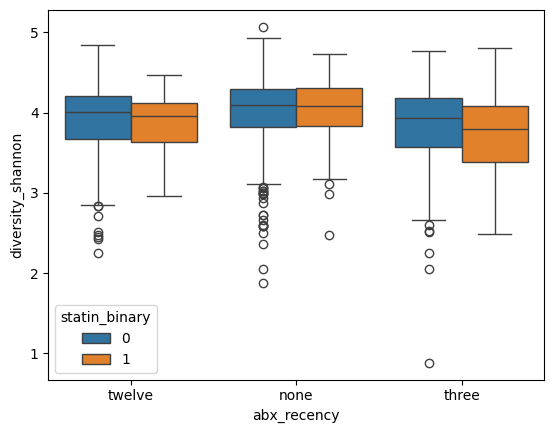

In [137]:
sns.boxplot(data=abx_covar_stool_basic_statin, x='abx_recency', y='diversity_shannon', hue='statin_binary')

In [138]:
labs_a1c_ldl = labs[[
    'public_client_id',
    'days_in_program',
    'vendor',
    'GLYCOHEMOGLOBINA1C',
    'LDL_CHOLCALCULATION']].copy()

In [139]:
abx_covar_stool_basic_statin = abx_covar_stool_basic_statin.sort_values(by="days_in_program")
abx_covar_stool_all_statin = abx_covar_stool_all_statin.sort_values(by="days_in_program")
labs_a1c_ldl = labs_a1c_ldl.sort_values(by="days_in_program")

# Merge with all covars
abx_covar_stool_statin_labs_a = pd.merge_asof(
    abx_covar_stool_all_statin, labs_a1c_ldl, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30)

# Merge with basic covars
abx_covar_stool_statin_labs_b = pd.merge_asof(
    abx_covar_stool_basic_statin, labs_a1c_ldl, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30)

<Axes: xlabel='abx_recency', ylabel='GLYCOHEMOGLOBINA1C'>

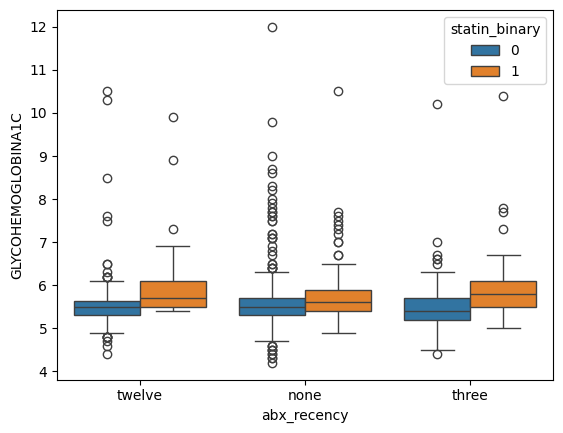

In [140]:
sns.boxplot(data=abx_covar_stool_statin_labs_b, x='abx_recency', y='GLYCOHEMOGLOBINA1C', hue='statin_binary')

In [141]:
abx_covar_stool_statin_labs_a = abx_covar_stool_statin_labs_a.drop(columns='diversity_shannon')
abx_covar_stool_statin_labs_b = abx_covar_stool_statin_labs_b.drop(columns='diversity_shannon')

In [143]:
abx_covar_stool_statin_labs_a.to_csv('data/abx_covariates_with_statins_a1c_all_covars.csv', index=False)
abx_covar_stool_statin_labs_b.to_csv('data/abx_covariates_with_statins_a1c_base_covars.csv', index=False)